# Práctica I — Aprendizaje Estadístico (2026/2027)

## Análisis de salud cardiometabólica con NHANES

**Dataset:** `data/nhanes_cardiometabolic_clean.csv` — National Health and Nutrition Examination Survey (CDC, EE. UU.).

**Estructura del trabajo:**

1. Selección del conjunto de datos
2. Exploración de los datos
3. Regresión lineal (simple y múltiple)
4. Selección y regularización: Ridge y Lasso
5. Análisis mediante PCA (y extensión PCR/PLS)
6. Regresión logística
7. Una única base de datos
8. Conclusiones

Se usa **una única base de datos**, ya que sus características permiten plantear razonablemente todos los problemas (regresión, regularización, reducción de dimensión y clasificación binaria).

## 1. Selección del conjunto de datos

Se ha elegido el dataset consolidado de **NHANES** (National Health and Nutrition Examination Survey, CDC), descargado directamente de <https://wwwn.cdc.gov/nchs/nhanes/> (dominio público). Reúne datos de **examen físico, cuestionarios y analíticas de laboratorio** de una muestra representativa de la población de EE. UU.

Es un dataset idóneo para esta práctica porque:
- contiene una respuesta cuantitativa natural (`sbp`, presión arterial sistólica) y otra binaria (`hypertension_dx`);
- tiene **muchos predictores numéricos correlacionados** (lípidos, hemograma, bioquímica), lo que motiva Ridge/Lasso y PCA;
- combina variables cuantitativas y cualitativas.

El script `get_data.py` genera el archivo `data/nhanes_cardiometabolic_clean.csv` (10.739 adultos de ≥ 20 años × 73 columnas con nombres legibles).

## 2. Exploración de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import skew

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve)

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 6)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("data/nhanes_cardiometabolic_clean.csv")
print("Número de observaciones:", df.shape[0])
print("Número de variables:", df.shape[1])
df.head()

Número de observaciones: 10739
Número de variables: 73


,seqn,cycle,psu,strata,wt_mec,wt_fasting,fasting_subsample,age,sex,race_eth,...,baso_pct,rbc,hemoglobin,hematocrit,mcv,mch,mchc,rdw,platelets,mpv
0,83732,2015-2016,1,125,67814.753703,NaN,False,62,male,nh_white,...,0.5,4.93,15.2,44.7,90.8,30.8,34.0,13.9,181.0,8.3
1,83733,2015-2016,1,125,12641.212964,27361.171665,True,53,male,nh_white,...,1.8,4.89,17.5,49.7,101.8,35.8,35.1,13.4,170.0,9.6
2,83734,2015-2016,1,131,6287.919409,12735.546850,True,78,male,nh_white,...,0.9,4.18,12.4,37.9,90.8,29.6,32.6,14.7,223.0,9.0
3,83735,2015-2016,1,131,51039.317254,NaN,False,56,female,nh_white,...,0.9,4.54,12.8,40.1,88.3,28.2,31.9,13.1,280.0,9.1
4,83736,2015-2016,2,126,9117.368109,19089.755435,True,42,female,nh_black,...,0.2,4.16,12.1,36.5,87.8,29.1,33.2,12.3,275.0,7.7


### Descripción de las variables

Las variables se agrupan en los siguientes bloques (los nombres ya están "traducidos" de los códigos originales del CDC):

| Grupo | Columnas |
|---|---|
| Diseño muestral | `seqn`, `cycle`, `psu`, `strata`, `wt_mec`, `wt_fasting`, `fasting_subsample` |
| Demografía | `age`, `sex`, `race_eth`, `education`, `income_poverty_ratio` |
| Exploración física | `sbp`, `dbp` (medias), `sbp1`, `dbp1`, `pulse`, `weight`, `height`, `bmi`, `waist` |
| Cuestionarios | `smoking`, `diabetes_dx`, `hypertension_dx`, `bp_meds`, `chol_meds` |
| Lípidos y glucosa | `total_chol`, `hdl`, `ldl`, `triglycerides`, `glucose_fasting`, `insulin`, `hba1c` |
| Inflamación | `hs_crp` |
| Hígado | `alt`, `ast`, `alp`, `ggt`, `ldh`, `bilirubin`, `albumin`, `total_protein`, `globulin` |
| Riñón | `creatinine`, `bun`, `uric_acid` |
| Electrolitos/minerales | `sodium`, `potassium`, `chloride`, `bicarbonate`, `calcium`, `phosphorus`, `iron`, `osmolality` |
| Bioquímica sin ayuno | `glucose_serum`, `chol_serum`, `trig_serum`, `cpk` |
| Hemograma | `wbc`, `lymph_pct`, `mono_pct`, `neut_pct`, `eos_pct`, `baso_pct`, `rbc`, `hemoglobin`, `hematocrit`, `mcv`, `mch`, `mchc`, `rdw`, `platelets`, `mpv` |

Las variables de la **submuestra en ayunas** (`ldl`, `triglycerides`, `glucose_fasting`, `insulin`) solo se midieron en la sesión de mañana (~4.500 adultos).

### Variables cuantitativas y cualitativas

In [3]:
categorical = df.select_dtypes(include=["object"]).columns.tolist()
quantitative = df.select_dtypes(include=[np.number]).columns.tolist()

print("Cualitativas (", len(categorical), "):", categorical)
print()
print("Cuantitativas (", len(quantitative), "). Primeras 20:", quantitative[:20])

Cualitativas ( 9 ): ['cycle', 'sex', 'race_eth', 'education', 'smoking', 'diabetes_dx', 'hypertension_dx', 'bp_meds', 'chol_meds']

Cuantitativas ( 63 ). Primeras 20: ['seqn', 'psu', 'strata', 'wt_mec', 'wt_fasting', 'age', 'income_poverty_ratio', 'sbp', 'sbp1', 'dbp', 'dbp1', 'pulse', 'weight', 'height', 'bmi', 'waist', 'total_chol', 'hdl', 'ldl', 'triglycerides']


/tmp/ipykernel_152766/1163575259.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=["object"]).columns.tolist()


In [4]:
# Resumen numérico de algunas variables relevantes
df[["age", "bmi", "sbp", "dbp", "total_chol", "hdl", "hba1c", "hs_crp"]].describe().round(2)

,age,bmi,sbp,dbp,total_chol,hdl,hba1c,hs_crp
count,10739.00,10581.00,10314.00,10287.00,10094.00,10094.00,10219.00,10042.00
mean,50.42,29.69,126.28,71.49,189.25,53.75,5.86,4.27
std,17.71,7.24,19.26,11.87,41.51,16.73,1.14,8.25
min,20.00,14.20,72.70,8.00,76.00,6.00,3.80,0.08
25%,35.00,24.70,112.70,64.00,161.00,42.00,5.30,0.83
50%,51.00,28.50,123.30,71.30,186.00,51.00,5.60,2.00
75%,65.00,33.40,136.00,78.70,214.00,63.00,6.00,4.60
max,80.00,86.20,238.00,138.70,545.00,226.00,17.00,188.50


### Visualizaciones relevantes

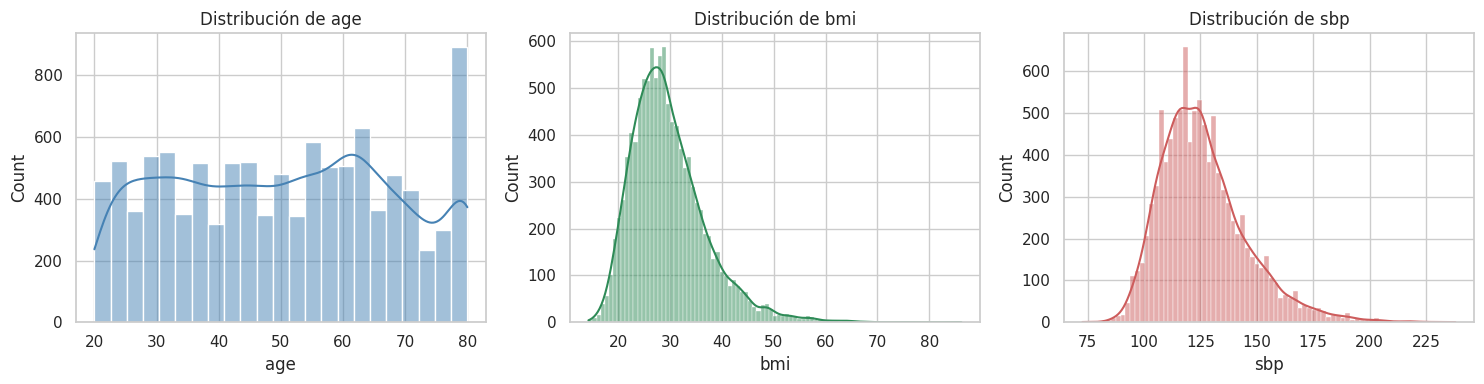

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var, color in zip(axes, ["age", "bmi", "sbp"], ["steelblue", "seagreen", "indianred"]):
    sns.histplot(data=df, x=var, kde=True, color=color, ax=ax)
    ax.set_title(f"Distribución de {var}")
plt.tight_layout()
plt.show()

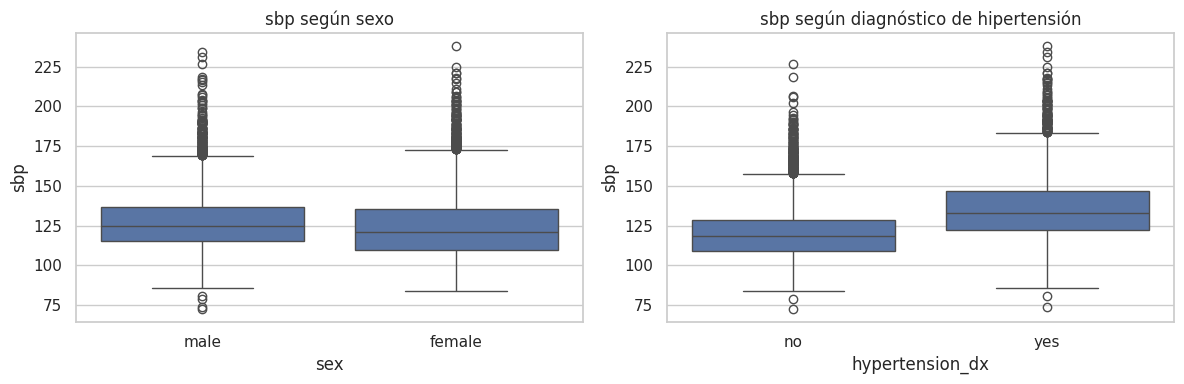

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="sex", y="sbp", ax=axes[0])
axes[0].set_title("sbp según sexo")
sns.boxplot(data=df, x="hypertension_dx", y="sbp", ax=axes[1])
axes[1].set_title("sbp según diagnóstico de hipertensión")
plt.tight_layout()
plt.show()

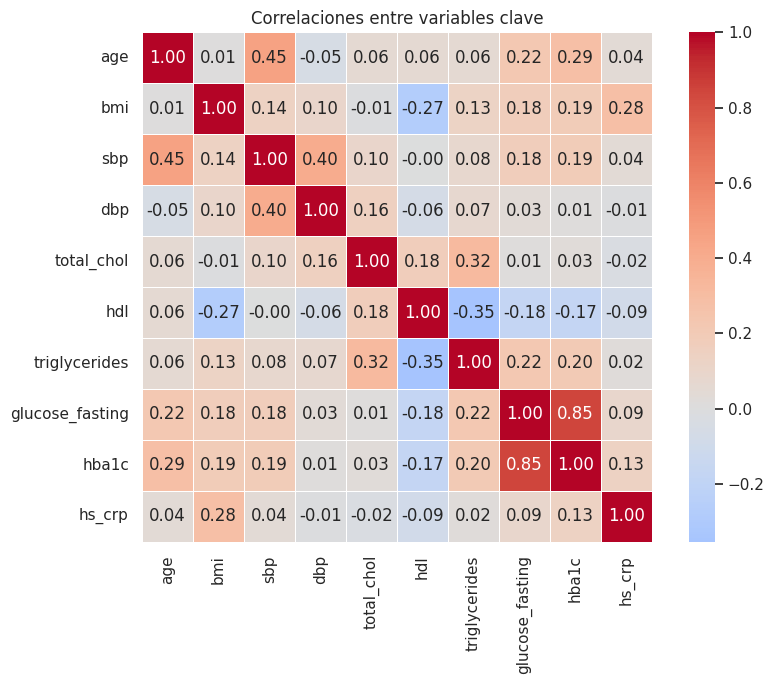

In [7]:
# Correlación entre biomarcadores clave (pairwise: ignora NA)
key = ["age", "bmi", "sbp", "dbp", "total_chol", "hdl", "triglycerides",
       "glucose_fasting", "hba1c", "hs_crp"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[key].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlaciones entre variables clave")
plt.tight_layout()
plt.show()

### Valores ausentes

In [8]:
missing = df.isna().mean().sort_values(ascending=False)
print("Variables con mayor proporción de ausentes (%):")
print((missing.head(15) * 100).round(1).to_string())

print()
print("Observaciones sin ningún valor ausente:", df.dropna().shape[0], "de", df.shape[0])

Variables con mayor proporción de ausentes (%):
chol_meds               71.9
ldl                     57.2
triglycerides           56.7
insulin                 55.3
glucose_fasting         54.5
wt_fasting              52.1
income_poverty_ratio    11.8
dbp1                     9.2
sbp1                     8.6
ldh                      7.3
hs_crp                   6.5
ast                      6.4
waist                    6.4
cpk                      6.4
globulin                 6.3

Observaciones sin ningún valor ausente: 989 de 10739


**Discusión de los ausentes:**

- Las 4 variables de la **submuestra en ayunas** (`ldl`, `triglycerides`, `glucose_fasting`, `insulin`) tienen ~55 % de NA **por diseño**: solo se midieron en la sesión de mañana. No son "datos perdidos" en el sentido habitual, sino una subpoblación.
- `income_poverty_ratio` (~12 %) y algunas lecturas de presión (`sbp1`, `dbp1`) también presentan NA.
- Estrategia: en los modelos se trabaja con **casos completos** (`dropna`) sobre el subconjunto de variables elegido, y se evita incluir las variables de ayunas cuando no es necesario para conservar más observaciones. Se menciona como limitación el no imputar.

### Anomalías y aspectos relevantes

In [9]:
# 1) globulin es una combinación lineal exacta de total_protein y albumin
g = df[["globulin", "total_protein", "albumin"]].dropna()
print("globulin == total_protein - albumin :",
      np.allclose(g["globulin"], g["total_protein"] - g["albumin"]))

# 2) Asimetría de los biomarcadores
num_vars = ["age", "bmi", "sbp", "total_chol", "hdl", "triglycerides", "insulin",
            "hs_crp", "ggt", "alt", "cpk", "glucose_fasting"]
sk = pd.Series({c: skew(df[c].dropna()) for c in num_vars}).sort_values(ascending=False)
print()
print("Asimetría (skewness) de variables seleccionadas:")
print(sk.round(2).to_string())

globulin == total_protein - albumin : True

Asimetría (skewness) de variables seleccionadas:
cpk                20.58
ggt                12.66
triglycerides       9.09
insulin             8.51
hs_crp              8.22
alt                 4.58
glucose_fasting     3.87
hdl                 1.22
bmi                 1.20
sbp                 1.03
total_chol          0.73
age                 0.02


**Anomalías detectadas:**

- **Combinación lineal exacta:** `globulin = total_protein − albumin`. No debe incluirse junto a las otras dos en un modelo (hace singular la matriz de diseño).
- **Colas largas:** `triglycerides`, `insulin`, `hs_crp`, `ggt`, `alt`, `cpk` presentan asimetría fuerte (valores muy altos en pocos individuos). Se aplicará `log(1+x)` antes de estandarizar.
- **Multicolinealidad intencionada:** pares casi redundantes como `total_chol`–`chol_serum` (r≈0.99), `hemoglobin`–`hematocrit` (0.97), `sodium`–`osmolality` (0.81), `ast`–`alt` (0.73). Esto motiva el uso de Ridge/Lasso y PCA.
- **Medicación:** quien toma antihipertensivos (`bp_meds`) o estatinas (`chol_meds`) tiene la PA/colesterol tratados; es una limitación a tener en cuenta al interpretar.

## 3. Regresión lineal

### 3.1 Variable respuesta y relación con los predictores

Se elige como **respuesta cuantitativa** la presión arterial sistólica `sbp` (mmHg). Es una variable continua, con interés clínico directo y disponible para la mayoría de individuos (solo ~4 % de NA).

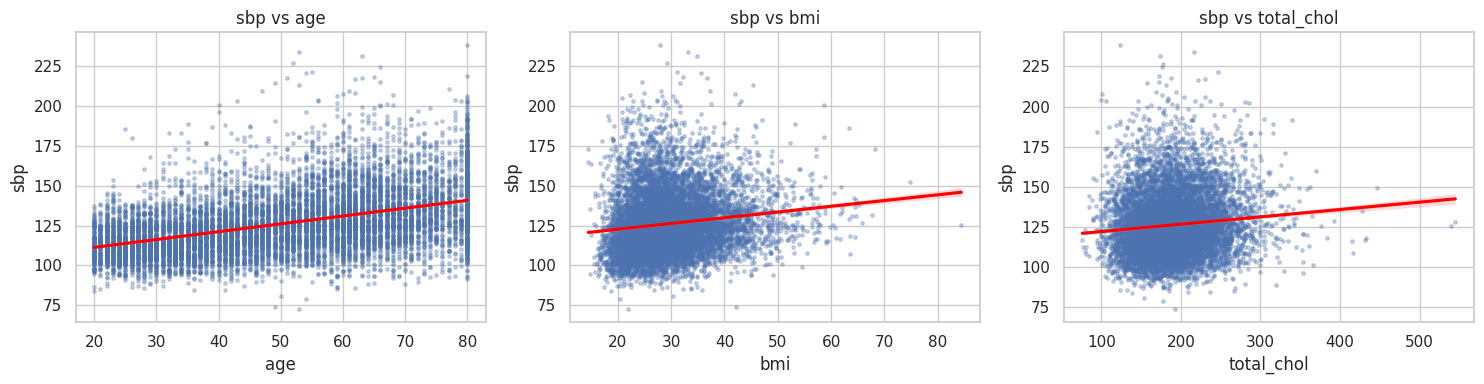

In [10]:
resp = "sbp"
# Relación gráfica de sbp con algunos predictores
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, ["age", "bmi", "total_chol"]):
    d = df[[resp, var]].dropna()
    sns.regplot(data=d, x=var, y=resp, scatter_kws={"s": 6, "alpha": 0.3}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"{resp} vs {var}")
plt.tight_layout()
plt.show()

### 3.2 Regresión lineal simple (`sbp ~ age`)

La edad es el predictor más natural de la presión arterial. Ajustamos el modelo simple y lo interpretamos.

In [11]:
d_simple = df[[resp, "age"]].dropna()
X_s = sm.add_constant(d_simple["age"])
model_simple = sm.OLS(d_simple[resp], X_s).fit()
print(model_simple.summary())

                            OLS Regression Results                            
Dep. Variable:                    sbp   R-squared:                       0.204
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     2642.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:20:58   Log-Likelihood:                -43969.
No. Observations:               10314   AIC:                         8.794e+04
Df Residuals:                   10312   BIC:                         8.796e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        101.4229      0.512    197.973      0.0

**Interpretación del modelo simple:**

$$\widehat{sbp} = 101.42 + 0.492 \cdot age$$

- **Intercepto (101.42):** presión sistólica media estimada para `age = 0` (sin interpretación clínica directa).
- **Pendiente (0.492):** por cada año adicional de edad, la presión sistólica media aumenta ~0.49 mmHg (estadísticamente significativo, p ≈ 0).
- **Calidad del ajuste:** R² = 0.204, es decir, la edad por sí sola explica ~20 % de la variabilidad de `sbp`.

Con este modelo, una persona de 20 años tendría en media ≈ 111 mmHg y una de 80 ≈ 141 mmHg.

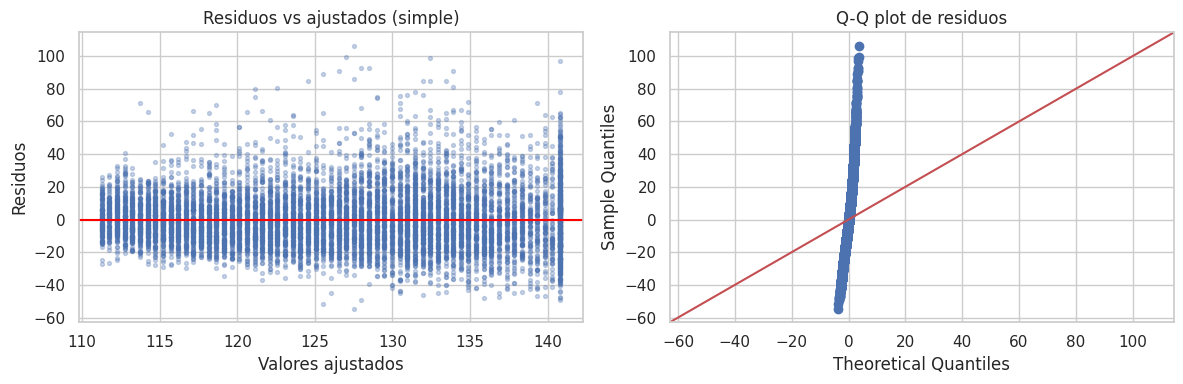

In [12]:
# Residuos del modelo simple
fitted = model_simple.fittedvalues
resid = model_simple.resid
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted, resid, s=8, alpha=0.3)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Valores ajustados"); axes[0].set_ylabel("Residuos")
axes[0].set_title("Residuos vs ajustados (simple)")
sm.qqplot(resid, line="45", ax=axes[1])
axes[1].set_title("Q-Q plot de residuos")
plt.tight_layout()
plt.show()

### 3.3 Regresión lineal múltiple

Añadimos `bmi`, `total_chol`, `hdl`, `sex` y `smoking`. No se incluyen todas las variables, sino las que se consideran más relevantes para explicar la presión arterial.

In [13]:
cols = [resp, "age", "bmi", "total_chol", "hdl", "sex", "smoking"]
d_multi = df[cols].dropna()
d_multi = pd.get_dummies(d_multi, columns=["sex", "smoking"], drop_first=True)

y_m = d_multi[resp]
X_m = d_multi.drop(columns=resp)
X_m_const = sm.add_constant(X_m)

model_multi = sm.OLS(y_m, X_m_const).fit()
print(model_multi.summary())

                            OLS Regression Results                            
Dep. Variable:                    sbp   R-squared:                       0.236
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     423.5
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:20:59   Log-Likelihood:                -40657.
No. Observations:                9620   AIC:                         8.133e+04
Df Residuals:                    9612   BIC:                         8.139e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             81.8482      1.433     57.

**Interpretación del modelo múltiple** (R² = 0.236, n = 9.620):

- **`age` (+0.488):** el predictor más relevante; ~0.49 mmHg más de `sbp` por año, manteniendo el resto constante.
- **`bmi` (+0.394):** ~0.39 mmHg más por cada unidad de IMC.
- **`total_chol` (+0.034) y `hdl` (+0.018):** efectos pequeños; el colesterol apenas desplaza la PA en esta muestra.
- **`sex_male` (+3.09):** los hombres tienen en media ~3 mmHg más que las mujeres, a igualdad del resto de variables.
- **`smoking_former` (−2.14) / `smoking_never` (−0.85):** respecto a los fumadores actuales (categoría de referencia).

**Comparación simple vs múltiple:** el R² pasa de 0.204 a 0.236. La edad apenas cambia su coeficiente (0.492 → 0.488), lo que indica que no estaba "absorbiendo" el efecto de las otras variables. El resto de predictores añaden poca capacidad explicativa adicional.

### 3.4 Predicciones para nuevas observaciones

In [14]:
# Nueva observación: mujer, 55 años, IMC 28, colesterol total 200, HDL 55, no fumadora
nueva = pd.DataFrame([{"age": 55, "bmi": 28, "total_chol": 200, "hdl": 55,
                       "sex_male": 0, "smoking_former": 0, "smoking_never": 1}])[X_m.columns]
pred_nueva = model_multi.predict(sm.add_constant(nueva, has_constant="add"))[0]
print(f"Predicción de sbp para la nueva observación: {pred_nueva:.1f} mmHg")

Predicción de sbp para la nueva observación: 126.7 mmHg


In [15]:
# Evaluación predictiva simple vs múltiple (train/test)
from sklearn.metrics import mean_squared_error, r2_score

X_tr, X_te, y_tr, y_te = train_test_split(
    X_m_const, y_m, test_size=0.2, random_state=RANDOM_STATE)

ols_simple = sm.OLS(y_tr, X_tr[["const", "age"]]).fit()
ols_multi = sm.OLS(y_tr, X_tr).fit()

for name, model, cols_use in [("Simple", ols_simple, ["const", "age"]),
                              ("Múltiple", ols_multi, X_tr.columns)]:
    pred = model.predict(X_te[cols_use])
    print(f"{name:9s} -> MSE test = {mean_squared_error(y_te, pred):.1f} | "
          f"R² test = {r2_score(y_te, pred):.3f}")

Simple    -> MSE test = 297.3 | R² test = 0.217
Múltiple  -> MSE test = 289.0 | R² test = 0.239


## 4. Selección y regularización: Ridge y Lasso

### ¿Por qué regularizar?

El panel de biomarcadores tiene **multicolinealidad importante** (pares casi redundantes y una combinación lineal exacta, `globulin`). En presencia de colinealidad:

- los coeficientes de OLS son **inestables** (cambian mucho ante pequeñas variaciones de los datos);
- la varianza de los estimadores es alta.

La regularización (Ridge = penalización L2, Lasso = L1) encoge los coeficientes hacia cero, reduce la varianza y, en Lasso, **selecciona variables** poniendo coeficientes exactamente a cero.

**Aviso de fuga de información:** el escalado se incluye dentro de un `Pipeline`, de modo que en cada fold de la validación cruzada el `StandardScaler` se reajusta solo con los datos de entrenamiento.

In [16]:
# Panel numérico "sin ayunas" (sin las 4 variables de la submuestra en ayunas ni globulin)
panel = [
    "age", "bmi", "waist", "pulse",
    "total_chol", "hdl", "hba1c", "hs_crp",
    "albumin", "total_protein",
    "alt", "ast", "alp", "ggt", "ldh", "bilirubin", "cpk",
    "bun", "creatinine", "uric_acid",
    "sodium", "potassium", "chloride", "bicarbonate",
    "calcium", "phosphorus", "iron", "osmolality",
    "glucose_serum", "chol_serum", "trig_serum",
    "wbc", "rbc", "hemoglobin", "hematocrit", "mcv", "mch", "mchc", "rdw",
    "platelets", "mpv",
    "lymph_pct", "mono_pct", "neut_pct", "eos_pct", "baso_pct",
]
skewed = ["hs_crp", "ggt", "alt", "cpk", "trig_serum"]

data_pen = df[panel + ["sbp"]].copy()
for c in skewed:
    data_pen[c] = np.log1p(data_pen[c])
data_pen = data_pen.dropna()

X_pen = data_pen[panel]
y_pen = data_pen["sbp"]
print("Casos completos para Ridge/Lasso/PCA:", X_pen.shape)

Casos completos para Ridge/Lasso/PCA: (9075, 46)


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pen, y_pen, test_size=0.2, random_state=RANDOM_STATE)
print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)

cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

Entrenamiento: (7260, 46) | Test: (1815, 46)


In [18]:
# Modelo de referencia OLS
ols_pipe = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
ols_pipe.fit(X_train, y_train)
pred_ols = ols_pipe.predict(X_test)
print(f"OLS -> MSE test = {mean_squared_error(y_test, pred_ols):.1f} | "
      f"R² test = {r2_score(y_test, pred_ols):.3f}")

OLS -> MSE test = 236.5 | R² test = 0.281


In [19]:
alphas = np.logspace(-3, 5, 100)

ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])
ridge_search = GridSearchCV(ridge_pipe, {"model__alpha": alphas},
                            scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
ridge_search.fit(X_train, y_train)
print("Ridge: mejor alpha =", ridge_search.best_params_["model__alpha"],
      "| MSE CV =", round(-ridge_search.best_score_, 1))

Ridge: mejor alpha = 148.49682622544665 | MSE CV = 264.6


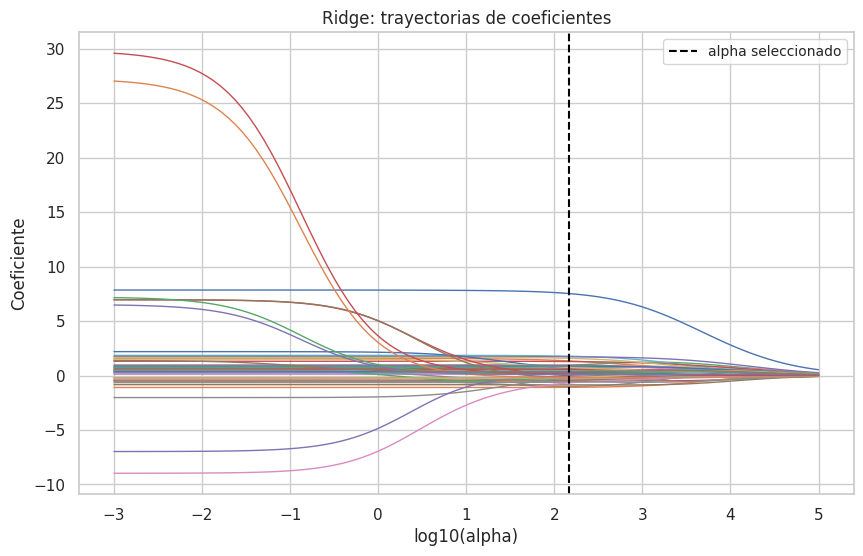

In [20]:
# Trayectoria de coeficientes Ridge
scaler_path = StandardScaler().fit(X_train)
X_train_scaled = scaler_path.transform(X_train)

ridge_coefs = np.asarray([Ridge(alpha=a).fit(X_train_scaled, y_train).coef_ for a in alphas])
plt.figure(figsize=(10, 6))
for j, name in enumerate(X_pen.columns):
    plt.plot(np.log10(alphas), ridge_coefs[:, j], lw=1)
plt.axvline(np.log10(ridge_search.best_params_["model__alpha"]), color="black",
            linestyle="--", label="alpha seleccionado")
plt.xlabel("log10(alpha)"); plt.ylabel("Coeficiente")
plt.title("Ridge: trayectorias de coeficientes")
plt.legend(loc="upper right", fontsize="small")
plt.show()

In [21]:
lasso_pipe = Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=20000))])
lasso_search = GridSearchCV(lasso_pipe, {"model__alpha": alphas},
                            scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
lasso_search.fit(X_train, y_train)
print("Lasso: mejor alpha =", lasso_search.best_params_["model__alpha"],
      "| MSE CV =", round(-lasso_search.best_score_, 1))

Lasso: mejor alpha = 0.02848035868435802 | MSE CV = 264.6


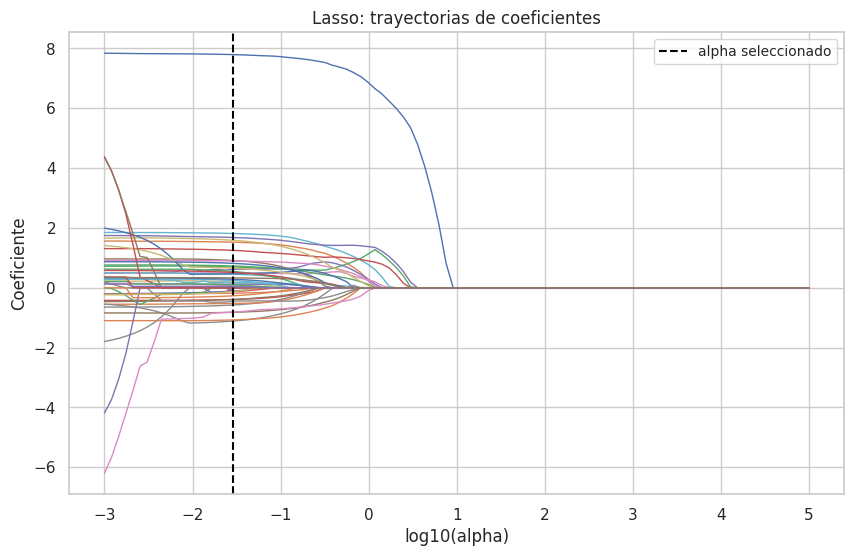

In [22]:
# Trayectoria de coeficientes Lasso
lasso_coefs = np.asarray([Lasso(alpha=a, max_iter=20000).fit(X_train_scaled, y_train).coef_ for a in alphas])
plt.figure(figsize=(10, 6))
for j, name in enumerate(X_pen.columns):
    plt.plot(np.log10(alphas), lasso_coefs[:, j], lw=1)
plt.axvline(np.log10(lasso_search.best_params_["model__alpha"]), color="black",
            linestyle="--", label="alpha seleccionado")
plt.xlabel("log10(alpha)"); plt.ylabel("Coeficiente")
plt.title("Lasso: trayectorias de coeficientes")
plt.legend(loc="upper right", fontsize="small")
plt.show()

In [23]:
# Variables que conserva Lasso
lasso_model = lasso_search.best_estimator_.named_steps["model"]
lasso_coef = pd.Series(lasso_model.coef_, index=X_pen.columns)
keep = lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False)
print("Nº de coeficientes no nulos:", (lasso_coef != 0).sum(), "de", len(lasso_coef))
print()
print(keep.round(3).to_string())

Nº de coeficientes no nulos: 42 de 46

age              7.795
total_protein    1.816
ldh              1.683
creatinine       1.590
bmi              1.526
ggt              1.252
bun             -1.112
potassium       -1.073
hdl              0.913
cpk              0.898
phosphorus      -0.818
trig_serum       0.818
mch             -0.812
alp              0.729
waist            0.696
glucose_serum    0.657
total_chol       0.616
hs_crp          -0.575
chloride         0.549
ast             -0.522
bicarbonate      0.515
hba1c            0.495
sodium           0.467
uric_acid        0.456
mchc            -0.446
pulse           -0.390
bilirubin       -0.389
baso_pct         0.331
mpv              0.286
lymph_pct       -0.268
platelets        0.243
albumin          0.188
wbc             -0.180
chol_serum       0.170
rdw             -0.126
calcium          0.123
alt             -0.109
hemoglobin      -0.108
mono_pct         0.096
iron             0.069
eos_pct          0.038
hematocrit      -0

**Interpretación de la selección de Lasso:** con el α óptimo (muy pequeño, ≈ 0.028), Lasso conserva **42 de 46** coeficientes. La señal está dominada por pocas variables (`age`, coeficiente ≈ 7.8 en escala estandarizada, seguida de `total_protein`, `ldh`, `creatinine`, `bmi`, `ggt`), así que apenas necesita regularización. Las 4 variables que **anula** son miembros de grupos redundantes: `osmolality` (muy correlacionada con `sodium`), `rbc` y `mcv` (correlacionadas con el resto del hemograma) y `neut_pct` (complementaria del resto de porcentajes leucocitarios, que suman 100). Ojo: que un coeficiente sea cero **no** demuestra que la variable no tenga relación con la respuesta; puede estar "representada" por otra variable correlacionada.

In [24]:
# Comparación final en test: OLS, Ridge, Lasso y (opcional) Elastic Net
elastic_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", ElasticNet(max_iter=10000))]),
    {"model__alpha": np.logspace(-3, 3, 20), "model__l1_ratio": [0.5, 0.9, 0.99, 1.0]},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
elastic_search.fit(X_train, y_train)

models = {
    "OLS": ols_pipe,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
    "Elastic Net": elastic_search.best_estimator_,
}
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({"Modelo": name,
                    "MSE test": mean_squared_error(y_test, pred),
                    "R² test": r2_score(y_test, pred)})
display(pd.DataFrame(results).sort_values("MSE test").round(3))

,Modelo,MSE test,R² test
2,Lasso,235.623,0.283
3,Elastic Net,235.919,0.282
1,Ridge,236.099,0.282
0,OLS,236.519,0.281


**Conclusión de la sección:** en este problema, con una señal dominada por `age` y `bmi`, la regularización no mejora de forma apreciable a OLS (los biomarcadores añaden poca capacidad predictiva y ya están bastante controlados). El valor de Lasso aquí es principalmente **interpretativo** (identifica las variables con efecto propio) y de **estabilidad** ante la colinealidad.

## 5. Análisis mediante PCA

Aplicamos PCA al **mismo panel cuantitativo** de la sección anterior (tras `log(1+x)` de las asimétricas). Es un análisis **no supervisado** (no interviene la respuesta `sbp`): sirve para resumir los ~46 biomarcadores correlacionados en unas pocas componentes.

Recordatorio: `PCA` de sklearn **solo centra** (no escala); por eso estandarizamos antes con `StandardScaler`.

In [25]:
X_scaled = StandardScaler().fit_transform(X_pen)
pca = PCA()
Z = pca.fit_transform(X_scaled)

loadings = pca.components_          # filas = componentes (direcciones φ)
var = pca.explained_variance_       # varianza de cada Zj
ratio = pca.explained_variance_ratio_

print("Resumen del modelo PCA (varianza explicada):")
summary_pca = pd.DataFrame({
    "Desv. típica": np.sqrt(var),
    "Varianza": var,
    "Proporción": ratio,
    "Acumulada": np.cumsum(ratio),
}, index=[f"PC{i+1}" for i in range(len(var))])
display(summary_pca.head(10).round(3))

Resumen del modelo PCA (varianza explicada):


,Desv. típica,Varianza,Proporción,Acumulada
PC1,2.227,4.961,0.108,0.108
PC2,2.041,4.168,0.091,0.198
PC3,1.820,3.312,0.072,0.270
PC4,1.605,2.577,0.056,0.326
PC5,1.565,2.450,0.053,0.380
PC6,1.421,2.018,0.044,0.424
PC7,1.412,1.993,0.043,0.467
PC8,1.318,1.737,0.038,0.505
PC9,1.275,1.625,0.035,0.540
PC10,1.243,1.546,0.034,0.574


In [26]:
# Verificación: explained_variance_ == valores singulares^2 / (n-1)
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)
print("¿explained_variance_ == S²/(n-1)?", np.allclose(var, S**2 / (len(X_scaled) - 1)))

# Justificación de la desviación típica de la primera componente
print()
print("Desviación típica de PC1:", round(np.sqrt(var[0]), 3))
print("Varianza total (suma autovalores):", round(var.sum(), 2), "= nº de variables:", X_pen.shape[1])

¿explained_variance_ == S²/(n-1)? True

Desviación típica de PC1: 2.227
Varianza total (suma autovalores): 46.01 = nº de variables: 46


**Justificación de la desviación típica de PC1:** al estar las variables estandarizadas, cada una tiene varianza 1 y la varianza total es `p` (el nº de variables, 46). La varianza de `Z1` es el primer autovalor y su desviación típica es su raíz cuadrada (≈ 2.23). Un autovalor ≫ 1 significa que PC1 concentra bastante más variabilidad que una sola variable original.

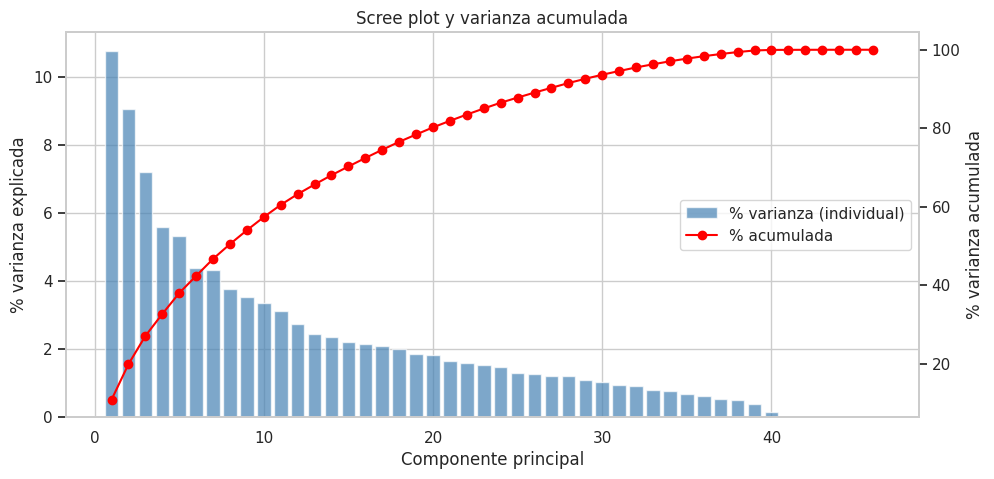

In [27]:
# Scree plot y varianza acumulada
fig, ax1 = plt.subplots(figsize=(11, 5))
comp_idx = np.arange(1, len(var) + 1)
ax1.bar(comp_idx, ratio * 100, color="steelblue", alpha=0.7, label="% varianza (individual)")
ax1.set_xlabel("Componente principal"); ax1.set_ylabel("% varianza explicada")

ax2 = ax1.twinx()
ax2.plot(comp_idx, np.cumsum(ratio) * 100, color="red", marker="o", label="% acumulada")
ax2.set_ylabel("% varianza acumulada")
ax2.grid(False)

l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lb1 + lb2, loc="center right")
plt.title("Scree plot y varianza acumulada")
plt.show()

In [28]:
loadings_df = pd.DataFrame(loadings.T, index=X_pen.columns,
                           columns=[f"PC{i+1}" for i in range(X_pen.shape[1])])
for pc in ["PC1", "PC2", "PC3"]:
    top = loadings_df[pc].reindex(loadings_df[pc].abs().sort_values(ascending=False).index).head(6)
    print(f"{pc} — variables con mayor |peso|:")
    print(top.round(3).to_string())
    print()

PC1 — variables con mayor |peso|:
hemoglobin    0.383
hematocrit    0.351
mch           0.287
rdw          -0.277
mchc          0.274
iron          0.269

PC2 — variables con mayor |peso|:
waist         0.358
bmi           0.316
hs_crp        0.265
hba1c         0.262
trig_serum    0.252
ggt           0.248

PC3 — variables con mayor |peso|:
osmolality    0.359
age           0.293
bun           0.287
sodium        0.262
mcv           0.257
rbc          -0.254



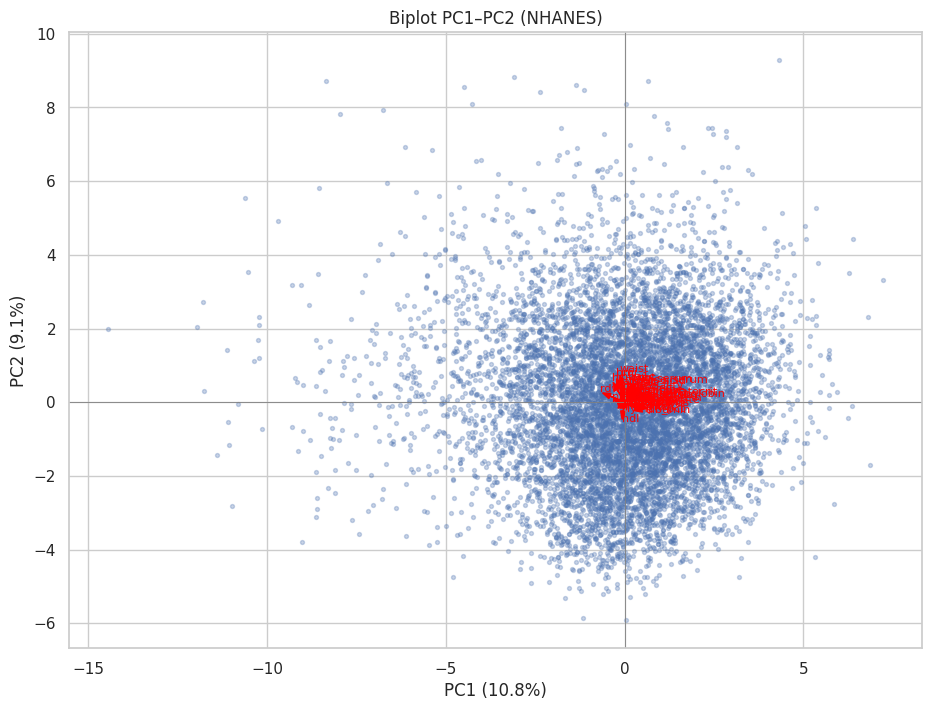

In [29]:
# Biplot PC1-PC2
comp = pca.components_.T * np.sqrt(pca.explained_variance_)
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(Z[:, 0], Z[:, 1], s=8, alpha=0.3)
for j, name in enumerate(X_pen.columns):
    ax.arrow(0, 0, comp[j, 0], comp[j, 1], color="red", width=0.002,
             head_width=0.15, length_includes_head=True)
    ax.text(comp[j, 0] * 1.12, comp[j, 1] * 1.12, name, color="red", fontsize=8)
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"PC1 ({ratio[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({ratio[1]*100:.1f}%)")
ax.set_title("Biplot PC1–PC2 (NHANES)")
plt.show()

**Interpretación de PCA:**

- **PC1** carga sobre todo en el **bloque hemograma**: `hemoglobin`, `hematocrit`, `mch`, `rdw`, `mchc`, `rbc`. Representa una dimensión de "tamaño/concentración globular".
- **PC2** tiende a recoger lípidos y/o función hepática.
- Según la varianza acumulada, las **primeras k componentes** explican la mayor parte de la variabilidad (consúltalo en la tabla de arriba). Como las variables están muy correlacionadas, bastan pocas componentes para resumir los datos.
- El **signo** de las cargas es arbitrario: un cambio de signo global de una componente no altera la interpretación.

PCA permite **resumir** los biomarcadores y detectar qué grupos de variables se mueven juntos, y se usa en PCR/PLS como paso previo a la regresión.

### Extensión (opcional): PCR y PLS

- **PCR:** regresión de `sbp` sobre las `m` primeras componentes de PCA (elegidas sin usar la respuesta).
- **PLS:** componentes construidas de forma **supervisada** (usando `sbp`), dando más peso a las variables más correlacionadas con la respuesta.

En ambos casos `m` se elige por validación cruzada, con el mismo esquema (mismos folds, misma métrica).

In [30]:
pcr_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("model", LinearRegression())]),
    {"pca__n_components": range(1, X_pen.shape[1] + 1)},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
pcr_search.fit(X_train, y_train)

n_pls = 20
pls_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("pls", PLSRegression(scale=False))]),
    {"pls__n_components": range(1, n_pls + 1)},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
pls_search.fit(X_train, y_train)

print("PCR: m =", pcr_search.best_params_["pca__n_components"], "| MSE CV =", round(-pcr_search.best_score_, 1))
print("PLS: m =", pls_search.best_params_["pls__n_components"], "| MSE CV =", round(-pls_search.best_score_, 1))

PCR: m = 40 | MSE CV = 264.6
PLS: m = 16 | MSE CV = 264.6


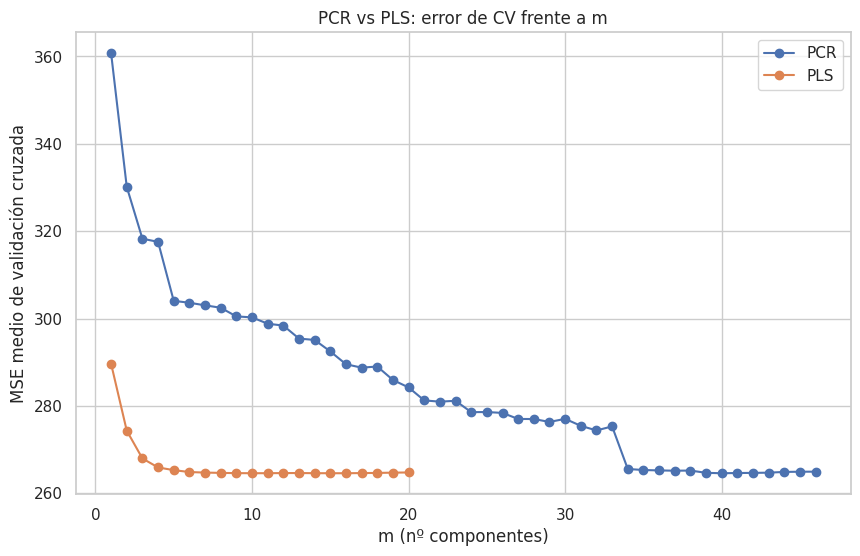

In [31]:
mses_pcr = -pcr_search.cv_results_["mean_test_score"]
mses_pls = -pls_search.cv_results_["mean_test_score"]

plt.plot(range(1, X_pen.shape[1] + 1), mses_pcr, marker="o", label="PCR")
plt.plot(range(1, n_pls + 1), mses_pls, marker="o", label="PLS")
plt.xlabel("m (nº componentes)"); plt.ylabel("MSE medio de validación cruzada")
plt.title("PCR vs PLS: error de CV frente a m")
plt.legend()
plt.show()

## 6. Regresión logística

### 6.1 Variable respuesta binaria

Se plantea un problema de **clasificación binaria**: predecir si una persona tiene **hipertensión diagnosticada** (`hypertension_dx`: `yes`/`no`). Es una variable binaria natural del dataset, así que no hace falta un segundo conjunto de datos.

In [32]:
df["hypertension_dx"].value_counts(dropna=False)

hypertension_dx
no     6719
yes    4005
NaN      15
Name: count, dtype: int64

In [33]:
# Predictores: edad, IMC, sexo, colesterol total, HDL y tabaco
cols_log = ["hypertension_dx", "age", "bmi", "sex", "total_chol", "hdl", "smoking"]
d_log = df[cols_log].dropna()
d_log = d_log[d_log["hypertension_dx"].isin(["yes", "no"])].copy()
d_log["y"] = (d_log["hypertension_dx"] == "yes").astype(int)
d_log = pd.get_dummies(d_log, columns=["sex", "smoking"], drop_first=True)

feats = [c for c in d_log.columns if c not in ("hypertension_dx", "y")]
X_log = d_log[feats]
y_log = d_log["y"]

print("Observaciones:", d_log.shape[0], "| Prevalencia de hipertensión:", round(y_log.mean(), 3))

Observaciones: 9938 | Prevalencia de hipertensión: 0.372


### 6.2 Ajuste e interpretación (odds ratios)

In [34]:
# statsmodels para interpretación (coeficientes y odds ratios)
X_log_const = sm.add_constant(X_log)
logit = sm.Logit(y_log, X_log_const).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 9938
Model:                          Logit   Df Residuals:                     9930
Method:                           MLE   Df Model:                            7
Date:                Tue, 27 Oct 2026   Pseudo R-squ.:                  0.1893
Time:                        18:24:12   Log-Likelihood:                -5317.9
converged:                       True   LL-Null:                       -6559.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -5.1269      0.218    -23.485      0.000      -5.555      -4.699
age                0.0628      0.002     39.297      0.000       0.060       0.066
bmi                0.0716      0.004

In [35]:
odds = np.exp(logit.params)
print("Odds ratios (exp(β)):")
print(odds.round(3).to_string())

Odds ratios (exp(β)):
const             0.006
age               1.065
bmi               1.074
total_chol        0.998
hdl               0.998
sex_male          1.008
smoking_former    0.723
smoking_never     0.659


**Interpretación:**

- **`age`** (OR ≈ 1.07 por año): cada año adicional multiplica por ~1.07 la odds de hipertensión (≈ +90 % por década). Es el predictor más fuerte.
- **`bmi`** (OR ≈ 1.07 por unidad de IMC): la obesidad aumenta claramente el riesgo.
- **`total_chol` y `hdl`** (OR ≈ 1.00): sin efecto apreciable sobre la odds de hipertensión diagnosticada (parte del efecto puede estar "tratado" por las estatinas).
- **`smoking`:** no fumar se asocia a menor odds que fumar actualmente (OR ≈ 0.72 exfumador, ≈ 0.66 nunca fumador, tomando a los fumadores actuales como referencia).
- **`sex_male`** (OR ≈ 1.01): sin diferencias apreciables entre sexos tras ajustar por el resto.

*Nota:* se interpreta el OR como el cambio multiplicativo en la odds por cada unidad de la variable, manteniendo el resto constante.

### 6.3 Evaluación: matriz de confusión y medidas

In [36]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X_log, y_log, test_size=0.2, random_state=RANDOM_STATE, stratify=y_log)

sc_log = StandardScaler().fit(X_tr)
lr = LogisticRegression(max_iter=1000).fit(sc_log.transform(X_tr), y_tr)

pred = lr.predict(sc_log.transform(X_te))
proba = lr.predict_proba(sc_log.transform(X_te))[:, 1]

cm = confusion_matrix(y_te, pred)
print("Matriz de confusión (filas = real, columnas = predicha):")
print(cm)
print()
print(f"Accuracy : {accuracy_score(y_te, pred):.3f}")
print(f"Precision: {precision_score(y_te, pred):.3f}")
print(f"Recall   : {recall_score(y_te, pred):.3f}")
print(f"F1-score : {f1_score(y_te, pred):.3f}")
print(f"AUC      : {roc_auc_score(y_te, proba):.3f}")

Matriz de confusión (filas = real, columnas = predicha):
[[1045  203]
 [ 321  419]]

Accuracy : 0.736
Precision: 0.674
Recall   : 0.566
F1-score : 0.615
AUC      : 0.803


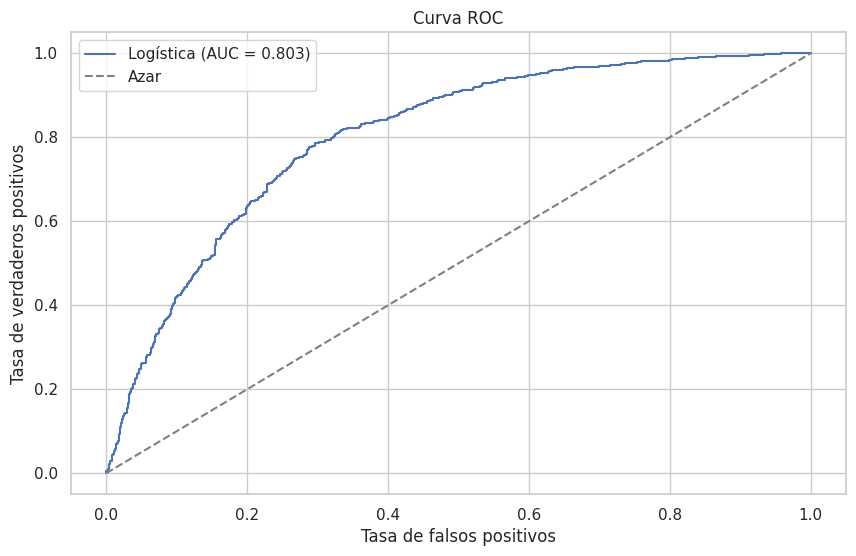

In [37]:
fpr, tpr, _ = roc_curve(y_te, proba)
plt.plot(fpr, tpr, label=f"Logística (AUC = {roc_auc_score(y_te, proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Azar")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC")
plt.legend()
plt.show()

**Interpretación de la evaluación:** con esta partición, la regresión logística obtiene accuracy ≈ 0.74 y AUC ≈ 0.80. La matriz de confusión ([[1045, 203], [321, 419]]) muestra buena **especificidad** (≈ 0.84: se clasifican bien los "no hipertensos") pero un **recall** más bajo (≈ 0.57), es decir, se escapan más casos reales de hipertensión. El AUC ≈ 0.80 indica una capacidad discriminativa razonable.

### 6.4 (Opcional) Comparación con LDA

In [38]:
lda = LinearDiscriminantAnalysis().fit(sc_log.transform(X_tr), y_tr)
pred_lda = lda.predict(sc_log.transform(X_te))
proba_lda = lda.predict_proba(sc_log.transform(X_te))[:, 1]

print("LDA:")
print(f"  Accuracy: {accuracy_score(y_te, pred_lda):.3f}")
print(f"  AUC     : {roc_auc_score(y_te, proba_lda):.3f}")

LDA:
  Accuracy: 0.737
  AUC     : 0.803


## 7. ¿Una o varias bases de datos?

Se ha utilizado **una única base de datos** (NHANES), ya que permite plantear razonablemente todos los problemas:

- **Regresión lineal:** `sbp` como respuesta cuantitativa.
- **Regularización:** panel de biomarcadores correlacionados.
- **PCA:** el mismo panel cuantitativo.
- **Regresión logística:** `hypertension_dx` como respuesta binaria (no ha sido necesario un segundo dataset).

A lo largo del trabajo, los modelos predictivos se han evaluado separando entrenamiento/test (20 % reservado para la evaluación final) y usando validación cruzada únicamente para **seleccionar hiperparámetros** (α de Ridge/Lasso, nº de componentes de PCR/PLS), nunca para la evaluación final.

## 8. Conclusiones

- **Relaciones encontradas:** la **edad** es el principal factor asociado a la presión arterial sistólica (`sbp ~ age + 0.49 mmHg/año`); el **IMC** también la aumenta (~0.39 mmHg por unidad). En la hipertensión, `age` y `bmi` son los predictores más relevantes (OR ≈ 1.06 por unidad/año).
- **Variables más relevantes:** `age` y `bmi` de forma consistente en regresión, Lasso y logística. Lasso confirma que el resto de biomarcadores aportan poco una vez controladas esas dos.
- **Diferencias entre modelos:** Ridge/Lasso apenas mejoran a OLS en test (MSE test 236.5 → 235.6), porque la señal está dominada por pocas variables y la colinealidad ya está controlada; su valor es de estabilidad e interpretación (Lasso anula variables redundantes). PLS alcanza el rendimiento de PCR con muchas menos componentes (16 frente a 40), al ser supervisado.
- **Qué aporta PCA:** resume los ~46 biomarcadores en pocas componentes; PC1 refleja el bloque del hemograma (`hemoglobin`, `hematocrit`, `mch`...), lo que muestra qué grupos de variables se mueven juntos y facilita interpretar la estructura de los datos.
- **Limitaciones:**
  - No se usan los **pesos muestrales** (`wt_mec`), por lo que no se pueden extrapolar prevalencias poblacionales.
  - Se **descartan** las filas con NA en vez de imputar, y se excluye la submuestra en ayunas.
  - **Medicación:** hipertensos/estatinas tienen la PA/colesterol tratados, lo que atenúa algunas relaciones.
  - `age` está **top-coded a 80**, limitando el extremo superior.

Las conclusiones anteriores se derivan de los resultados obtenidos en las secciones previas.